# Clean noisy GPS data and find stops

**Question.** My GPS traces contain glitches and long recording gaps. How do I clean them, and where did each person actually stop?

**You will get** a cleaned trajectory, a count of what each cleaning step removed, the places where each person stayed at least 20 minutes, and those places grouped into recurring locations per person.

**Prerequisites.** Basic familiarity with the trajectory table (see [Start with a trajectory](analyze-a-simple-trajectory.md)). The run-time table at the end shows the measured time of each phase of the run saved here; Colab was not measured. The run-time table at the end shows the numbers for your own run.

**Data.** [GeoLife](https://www.microsoft.com/en-us/download/details.aspx?id=52367), GPS tracks of Beijing residents collected by Microsoft Research Asia, sampled every 1 to 5 seconds. The full archive is 313 MB. `fastmob.data.load_geolife` reads only the first 25 trips of users 000, 001 and 002 straight from the public archive: about 4 MB and 105,000 position fixes. Check the dataset page for its terms of use before redistributing the data. If the download fails the notebook stops; it never substitutes other data.

> **Requires `fastmob` 0.3.4 or newer**, which provides the dataset loaders `fastmob.data.load_geolife` and `load_brightkite` (0.3.3 has them but caches GeoLife files across calls).

In [1]:
import time
from contextlib import contextmanager

_NOTEBOOK_START = time.perf_counter()
PHASES = {}


@contextmanager
def phase(name):
    """Add the wall-clock time of the block to PHASES[name]."""
    start = time.perf_counter()
    try:
        yield
    finally:
        PHASES[name] = PHASES.get(name, 0.0) + time.perf_counter() - start

In [2]:
with phase("setup"):
    get_ipython().run_line_magic("pip", "install -q 'fastmob>=0.3.4' pandas matplotlib")

In [3]:
import fastmob.data

assert hasattr(fastmob.data, "load_geolife") and hasattr(fastmob.data, "load_brightkite"), (
    "This notebook needs fastmob 0.3.4 or newer (older releases lack the dataset loaders or have a loader caching bug)."
)

## Load the data

GeoLife timestamps are in UTC and positions are decimal degrees (WGS 84). One row is one GPS fix.

In [4]:
import tempfile
from pathlib import Path

import fastmob
from fastmob.data import load_geolife

cache_status = "cached (files from an earlier run were reused)" if (Path(tempfile.gettempdir()) / "fastmob_data" / "geolife").exists() else "cold (nothing cached before this run)"

with phase("download and load"):
    traj = load_geolife(users=["000", "001", "002"], max_trips_per_user=25)

fixes = traj.to_pandas()
print(len(fixes), "fixes from", fixes["uid"].nunique(), "users,", fixes["datetime"].min(), "to", fixes["datetime"].max())
fixes.head()

105480 fixes from 3 users, 2008-10-23 02:53:04 to 2008-11-19 13:49:56


,uid,lat,lng,datetime
0,000,39.984702,116.318417,2008-10-23 02:53:04
1,000,39.984683,116.318450,2008-10-23 02:53:10
2,000,39.984686,116.318417,2008-10-23 02:53:15
3,000,39.984688,116.318385,2008-10-23 02:53:20
4,000,39.984655,116.318263,2008-10-23 02:53:25


## Remove implausible jumps

GPS receivers occasionally report a position far from the true one. `filter` finds points that would require an impossible speed and drops them. **Method choice:** the default `speed` method needs a maximum plausible speed. GeoLife includes walking, buses, cars, trains and some flights, so we use 200 km/h, which keeps fast ground transport but removes teleports. Use a lower value (for example 15 km/h) for walking-only data; a threshold that is too low would delete real movement.

In [5]:
with phase("analysis"):
    clean = fastmob.filter(fixes, max_speed_kmh=200)

removed = len(fixes) - len(clean)
print(f"removed {removed} of {len(fixes)} fixes ({removed / len(fixes):.2%}) at 200 km/h")

removed 193 of 105480 fixes (0.18%) at 200 km/h


Only a small share of fixes is implausible, so the cleaning is conservative. A stricter threshold removes more; always report the threshold you used.

In [6]:
with phase("analysis"):
    removed_by_threshold = {kmh: len(fixes) - len(fastmob.filter(fixes, max_speed_kmh=kmh)) for kmh in (60, 120, 200, 400)}
removed_by_threshold

{60: 5640, 120: 449, 200: 193, 400: 58}

The count drops as the threshold rises, which is the expected shape: the lower limits start deleting genuine vehicle movement. Choose the limit from the fastest mode in your data, not from the count.

## Split each trace at recording gaps

A device that is switched off leaves a gap, and the next fix may be kilometres away. `segment` labels each fix with a `segment_id` (restarting at 0 for each person) without dropping any rows. With `method="observation_gap"` a new segment starts whenever the pause between two fixes exceeds `gap_s` seconds. Here the limit is 30 minutes.

In [7]:
with phase("analysis"):
    segmented = fastmob.segment(clean, method="observation_gap", gap_s=30 * 60)

segments_per_user = segmented.groupby("uid")["segment_id"].nunique()
segments_per_user

uid
000    41
001    58
002    57
Name: segment_id, dtype: int64

Each person's trace splits into several continuous recordings. Segments are the right unit for anything that must not span a gap, such as a trip length. Other `method` values split on stops, speed changes, turns or fixed time windows; see the reference.

## Reduce the number of points

Continuous tracking produces many near-identical points when someone is stationary or moving in a straight line. Two functions thin the data differently:

- `compress` collapses runs of fixes that stay within `spatial_radius_km` of the run's first point, so it mainly removes the clutter from standing still.
- `simplify` keeps the shape of the path. The default `douglas_peucker` method drops points that deviate less than `epsilon_km` from the straight line.

Both keep the same columns.

In [8]:
with phase("analysis"):
    compressed = fastmob.compress(clean, spatial_radius_km=0.1)
    simplified = fastmob.simplify(clean, method="douglas_peucker", epsilon_km=0.01)

print(f"original   {len(clean):>7,} fixes")
print(f"compressed {len(compressed):>7,} fixes (radius 100 m)")
print(f"simplified {len(simplified):>7,} fixes (10 m tolerance)")

original   105,287 fixes
compressed   6,173 fixes (radius 100 m)
simplified   8,668 fixes (10 m tolerance)


Both remove more than 90% of the fixes. `compress` removes slightly more because GeoLife users spend long periods stationary; `simplify` keeps extra points wherever the path bends. Neither is lossless: use the reduced data for visualisation or storage, and compute measures that depend on time (waiting times, stop durations) on the cleaned data instead.

## Detect stops

A *stop* (a staypoint) is a period of at least `minutes_for_a_stop` minutes during which a person stays within `spatial_radius_km` of where they arrived. We use 20 minutes and 200 m. **Method choice:** the detector bridges missing data by default: if a device is switched off while the person is at a place, it may report a single very long stay. `no_data_for_minutes` discards any stay in progress when the data go silent for that long, so a stay can never span a long gap. We first run without it, then with 30 minutes.

In [9]:
with phase("analysis"):
    stops_open = fastmob.stay_locations(clean, minutes_for_a_stop=20, spatial_radius_km=0.2)
    stops = fastmob.stay_locations(clean, minutes_for_a_stop=20, spatial_radius_km=0.2, no_data_for_minutes=30)

for label, s in (("without a silence limit", stops_open), ("with a 30-minute silence limit", stops)):
    hours = (s["leaving_datetime"] - s["datetime"]).dt.total_seconds() / 3600
    print(f"{label}: {len(s)} stops, longest {hours.max():.1f} h, median {hours.median():.2f} h")

without a silence limit: 205 stops, longest 142.1 h, median 2.29 h
with a 30-minute silence limit: 72 stops, longest 5.3 h, median 0.47 h


Without a silence limit the longest stay lasts almost six days (142 hours): a device left on a desk, then switched off, looks like one continuous stay. With the limit, a stay that spans a silence is discarded rather than shortened, so there are fewer stops (72 instead of 205) and none lasts longer than about five hours; the 72 are the stops fully backed by data. Neither answer is universally right; the limit encodes what you believe a data gap means.

## Group stops into locations

People return to the same places. `cluster` assigns each stop a `cluster` label so repeated visits to one place share a label. It places stops on an H3 hexagonal grid and joins occupied cells that touch; `cluster_radius_km` only chooses the grid size, so it sets the scale of a place approximately, not as an exact distance, and a chain of touching cells becomes one place. Labels are meaningful within one person only: cluster 0 of one user is not cluster 0 of another.

In [10]:
with phase("analysis"):
    located = fastmob.cluster(stops, cluster_radius_km=0.2)

located.groupby("uid")["cluster"].agg(stops="size", places="nunique")

,stops,places
uid,,
000,10,5
001,22,14
002,40,15


Each user makes many more stops than they have distinct places, which is the signature of routine: the same few locations are visited repeatedly.

## Plot one user

Grey dots are the cleaned fixes of user 000; gold circles are their detected stops.

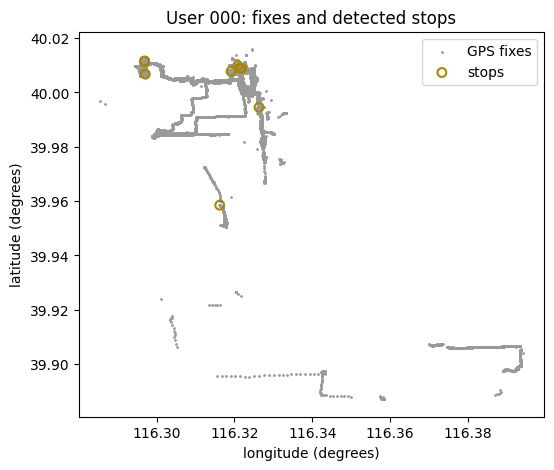

In [11]:
import matplotlib.pyplot as plt

with phase("plotting"):
    one = clean[clean["uid"] == "000"]
    one_stops = located[located["uid"] == "000"]
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(one["lng"], one["lat"], s=1, color="#999999", label="GPS fixes")
    ax.scatter(one_stops["lng"], one_stops["lat"], s=40, facecolors="none", edgecolors="#a98600", linewidths=1.5, label="stops")
    ax.set_xlabel("longitude (degrees)")
    ax.set_ylabel("latitude (degrees)")
    ax.legend()
    ax.set_title("User 000: fixes and detected stops")
    plt.show()

The stops sit on dense clusters of fixes: places where the person lingered, such as home or a workplace. Isolated fixes between clusters are movement.

## Interpretation and limits

- Cleaning, segmentation and stop detection all depend on thresholds. There is no correct value, only values justified by the transport modes, sampling rate and gap behaviour of your data. Report them with your results.
- This notebook used 3 of 182 users and 25 trips each. The counts above describe this subset, not GeoLife as a whole.
- Stops are inferred from position alone. A stop is not necessarily a purpose: waiting at traffic lights for 20 minutes is rare, but waiting in a car park is not a visit.
- Locations are per user. Merging them across users needs a shared definition of place (for example a common grid; see `latlng_to_h3`).

## Next steps

- Compute mobility measures on the cleaned data: [Measure individual mobility](measure-individual-mobility.md).
- Understand the staypoint hierarchy (positions, stops, trips, tours): [Stops and locations](staypoints-and-locations.md).

## Related API

[`load_geolife`](https://gefgu.github.io/fastmob/reference/data/#fastmob.data.load_geolife) ·
[`filter`](https://gefgu.github.io/fastmob/reference/preprocessing/#fastmob.preprocessing.filter) ·
[`segment`](https://gefgu.github.io/fastmob/reference/preprocessing/#fastmob.preprocessing.segment) ·
[`compress`](https://gefgu.github.io/fastmob/reference/preprocessing/#fastmob.preprocessing.compress) ·
[`simplify`](https://gefgu.github.io/fastmob/reference/preprocessing/#fastmob.preprocessing.simplify) ·
[`stay_locations`](https://gefgu.github.io/fastmob/reference/preprocessing/#fastmob.preprocessing.stay_locations) ·
[`cluster`](https://gefgu.github.io/fastmob/reference/preprocessing/#fastmob.preprocessing.cluster)

## Run time

Measured by the notebook's own wall clock. Saved timings were measured in a fresh local virtual environment (Python 3.10) with a pre-built wheel of fastmob 0.3.4 until that release is on PyPI; the setup row is the package installation; Colab was not measured. "download and load" includes reading the archive's file list, downloading the selected trip files and parsing them.

In [12]:
import datetime
import platform
from importlib.metadata import version

import pandas as pd

total = time.perf_counter() - _NOTEBOOK_START
measured = sum(PHASES.values())
timing = pd.DataFrame({"seconds": {**PHASES, "untimed cells and display": total - measured, "total notebook runtime": total}}).round(2)
print(timing.to_string())
print()
print("Download:", 'about 4 MB of the 313 MB GeoLife archive (HTTP range requests)')
print("Cache:", cache_status)
print("Rows analysed:", len(fixes))
print("Environment: Python", platform.python_version(), "| fastmob", version("fastmob"), "| pandas", version("pandas"),
      "| measured", datetime.datetime.now(datetime.timezone.utc).date().isoformat())

                           seconds
setup                        13.87
download and load            18.22
analysis                     14.96
plotting                      0.47
untimed cells and display     3.23
total notebook runtime       50.75

Download: about 4 MB of the 313 MB GeoLife archive (HTTP range requests)
Cache: cold (nothing cached before this run)
Rows analysed: 105480
Environment: Python 3.10.12 | fastmob 0.3.4 | pandas 2.3.3 | measured 2026-10-27
